## Imports e Configurações

In [1]:
import json
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from scipy.io import wavfile
from scipy.signal import butter, sosfiltfilt, resample_poly, spectrogram
from sklearn.model_selection import train_test_split

CLASSES = ["Present", "Unknown", "Absent"]
CLASS2IDX = {c: i for i, c in enumerate(CLASSES)}

@dataclass
class Config:
    data_dir: Path = Path("../data/circor")
    fs_target: int = 1000   # Hz (Nyquist = 500 Hz)
    band: tuple = (25, 400)        # passa-banda (Hz)
    win_sec: float = 5.0           # tamanho da janela (s)
    hop_sec: float = 2.5           # passo entre janelas (s)
    # --- log-mel / CNN 2D ---
    n_mels: int = 40
    frame_len: int = 128           # amostras (128 ms a 1 kHz)
    frame_step: int = 32           # amostras (32 ms)
    # --- RNN ---
    n_mfcc: int = 13
    rnn_frame_step: int = 64       # passo maior => sequências mais curtas (~77)
    seed: int = 42

    @property
    def wav_dir(self):
        return self.data_dir / "training_data"

    @property
    def csv_path(self):
        return self.data_dir / "training_data.csv"

CFG = Config()
print("CSV existe:", CFG.csv_path.exists(), "| pasta wav existe:", CFG.wav_dir.exists())

I0000 00:00:1793806648.905918    1565 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


CSV existe: True | pasta wav existe: True


## Metadados e split por paciente

O split é feito **por paciente** (todas as gravações de um paciente ficam no mesmo subconjunto) e **estratificado** pela classe `Murmur`. O resultado é guardado em `splits.json`, que deve ser commitado para todo o grupo usar o mesmo split.

In [2]:
def load_metadata(cfg: Config = CFG) -> pd.DataFrame:
    """Carrega o arquivo CSV com os metadados dos áudios."""
    df = pd.read_csv(cfg.csv_path)[["Patient ID", "Murmur"]].copy()
    df.columns = ["pid", "murmur"]
    df["pid"] = df["pid"].astype(str)
    df["y"] = df["murmur"].map(CLASS2IDX)
    assert df["y"].notna().all(), "Valores de Murmur inesperados"
    return df

def make_splits(meta: pd.DataFrame, val_size=0.15, test_size=0.15, seed=42):
    """Split estratificado POR PACIENTE (uma linha do meta = um paciente)."""
    pids, ys = meta["pid"].values, meta["y"].values
    trval, test = train_test_split(pids, test_size=test_size, stratify=ys, random_state=seed)
    y_traval = meta.set_index("pid").loc[trval, "y"].values
    train, val = train_test_split(trval, test_size=val_size / (1 - test_size), stratify=y_traval, random_state=seed)
    return {"train": list(train), "val": list(val), "test": list(test)}

def get_splits(meta, path="splits.json", seed=42):
    """Carrega o split guardado ou cria-o (todos no grupo devem usar o mesmo)."""
    path = Path(path)
    if path.exists():
        return json.loads(path.read_text())
    splits = make_splits(meta, seed=seed)
    path.write_text(json.dumps(splits))
    return splits

In [3]:
meta = load_metadata()
splits = get_splits(meta)

print(meta["murmur"].value_counts(normalize=True).round(3), "\n")
for k, v in splits.items():
    print(k, len(v), meta[meta.pid.isin(v)].murmur.value_counts().to_dict())

# Garantia: sem pacientes repetidos entre subconjuntos
assert not (set(splits["train"]) & set(splits["val"]))
assert not (set(splits["train"]) & set(splits["test"]))
assert not (set(splits["val"]) & set(splits["test"]))

murmur
Absent     0.738
Present    0.190
Unknown    0.072
Name: proportion, dtype: float64 

train 658 {'Absent': 485, 'Present': 125, 'Unknown': 48}
val 142 {'Absent': 105, 'Present': 27, 'Unknown': 10}
test 142 {'Absent': 105, 'Present': 27, 'Unknown': 10}


# Análise dos dados e espectrogramas

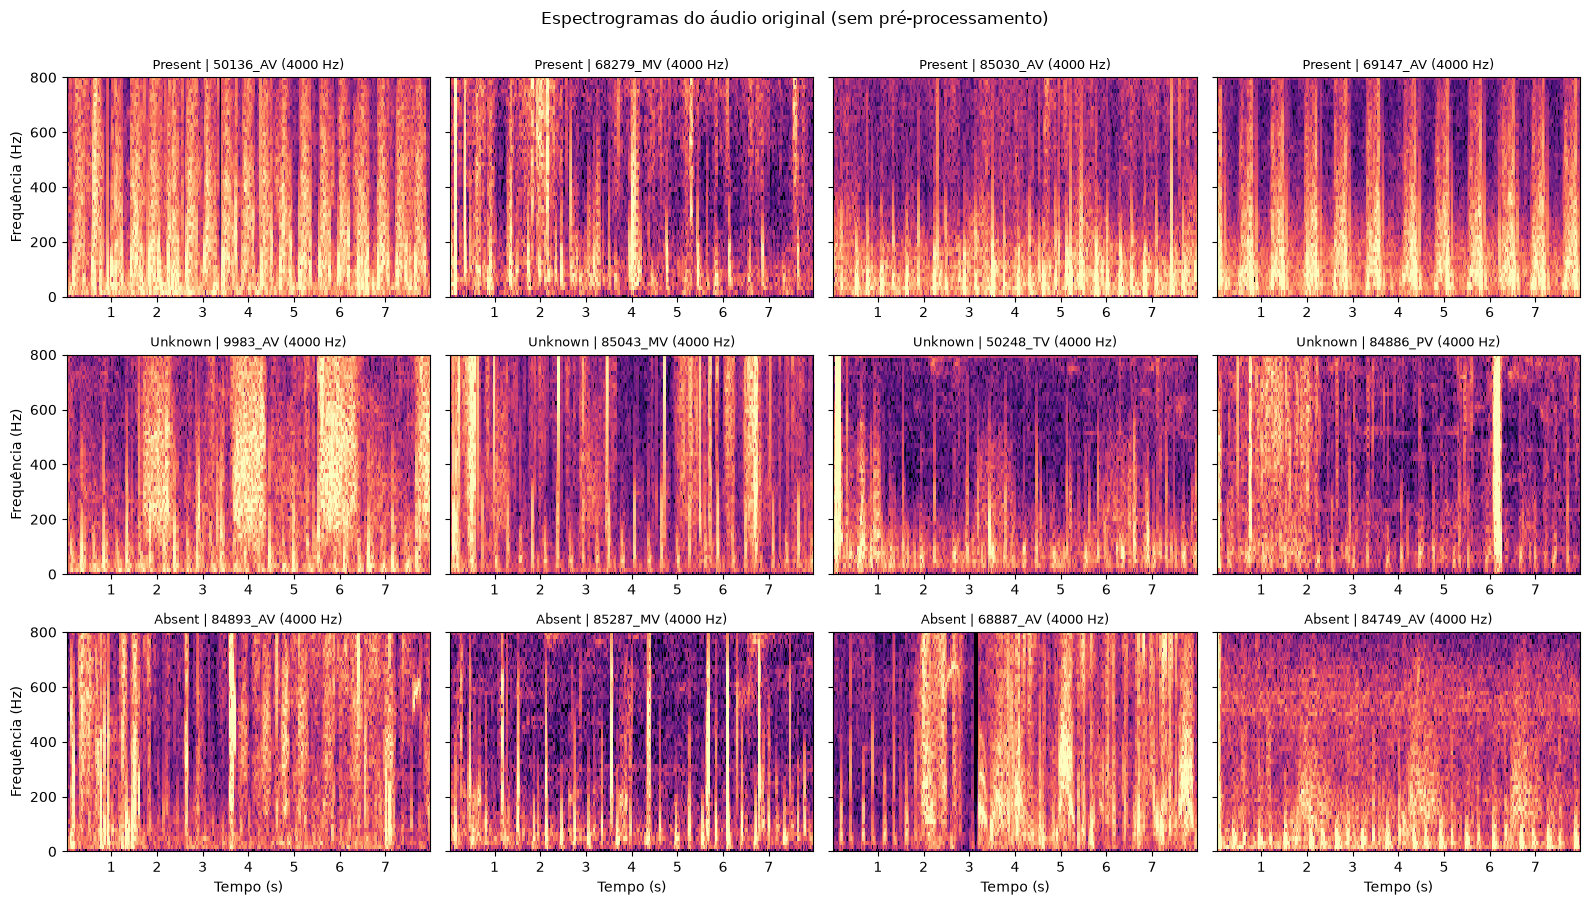

In [5]:
N_PER_CLASS = 4 #exemplos de cada classe
DUR = 8 #Segundos mostrados
rng = np.random.default_rng(0)
train_meta = meta[meta.pid.isin(splits["train"])] #explora só os de treino

fig, axes = plt.subplots(3, N_PER_CLASS, figsize = (4*N_PER_CLASS, 9), sharey=True)

for r, cls in enumerate(CLASSES):
    pids = rng.choice(train_meta[train_meta.murmur == cls].pid.values,
                      N_PER_CLASS, replace=False)
    for c, pid in enumerate(pids):
        wav = sorted(CFG.wav_dir.glob(f"{pid}_*.wav"))[0]
        fs, x = wavfile.read(wav)
        x = x.astype(np.float32)[: int(DUR * fs)]
        f, t, S = spectrogram(x, fs=fs, nperseg=256, noverlap=192)
        db = 10 * np.log10(S + 1e-10)
        vmin, vmax = np.percentile(db, [5, 99])
        ax = axes[r, c]
        ax.pcolormesh(t, f, db, shading="auto", cmap="magma", vmin=vmin, vmax=vmax)
        ax.set_ylim(0, 800)
        ax.set_title(f"{cls} | {wav.stem} ({fs} Hz)", fontsize=9)
        if c == 0: ax.set_ylabel("Frequência (Hz)")
        if r == 2: ax.set_xlabel("Tempo (s)")
plt.suptitle("Espectrogramas do áudio original (sem pré-processamento)", y=1.0)
plt.tight_layout(); plt.show()


Mostra que a mesma pessoa tem várias gravações (uma por local) e que o sopro pode ser mais visível num local do que noutro. É isto que justifica agregar por paciente.

Paciente: 84692 | locais com sopro: AV+MV+PV+TV


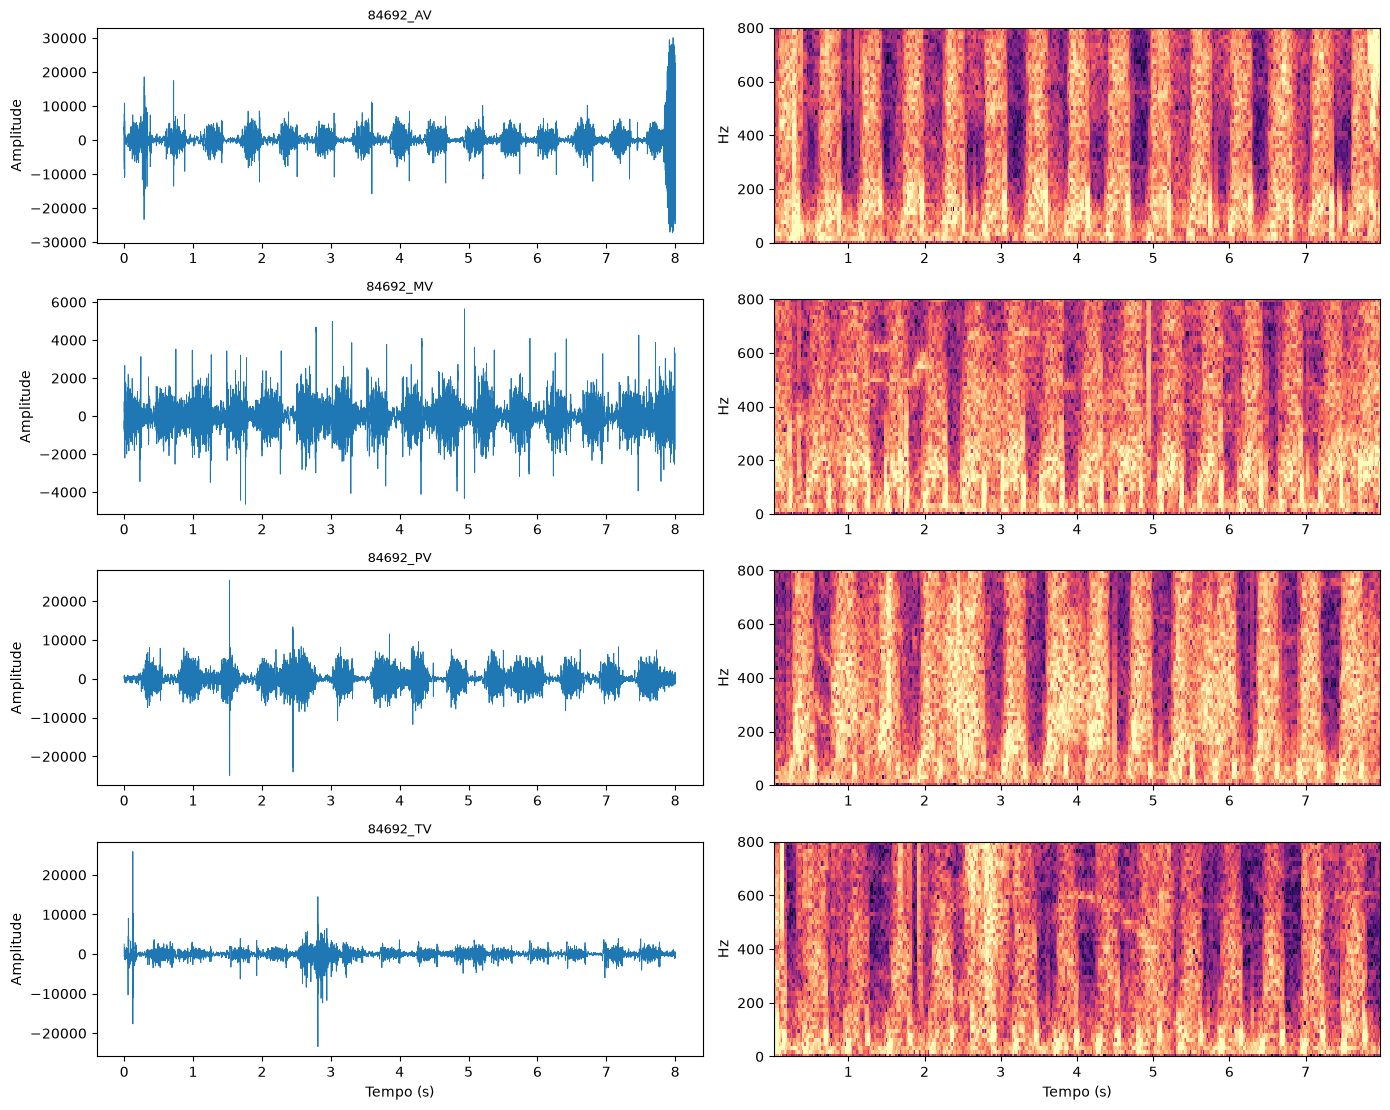

In [8]:
raw_meta = pd.read_csv(CFG.csv_path)
raw_meta["Patient ID"] = raw_meta["Patient ID"].astype(str)

pid = rng.choice(train_meta[train_meta.murmur == "Present"].pid.values)
print("Paciente:", pid,
      "| locais com sopro:", raw_meta.set_index("Patient ID").loc[pid, "Murmur locations"])

wavs = sorted(CFG.wav_dir.glob(f"{pid}_*.wav"))
fig, axes = plt.subplots(len(wavs), 2, figsize=(14, 2.8 * len(wavs)))
axes = np.atleast_2d(axes)
for (a_wave, a_spec), wav in zip(axes, wavs):
    fs, x = wavfile.read(wav)
    x = x.astype(np.float32)[: int(DUR * fs)]
    a_wave.plot(np.arange(len(x)) / fs, x, lw=0.6)
    a_wave.set_title(wav.stem, fontsize=9); a_wave.set_ylabel("Amplitude")
    f, t, S = spectrogram(x, fs=fs, nperseg=256, noverlap=192)
    db = 10 * np.log10(S + 1e-10)
    a_spec.pcolormesh(t, f, db, shading="auto", cmap="magma", vmin=np.percentile(db, 5), vmax=np.percentile(db, 99))
    a_spec.set_ylim(0, 800); a_spec.set_ylabel("Hz")
axes[-1, 0].set_xlabel("Tempo (s)"); axes[-1, 1].set_xlabel("Tempo (s)")
plt.tight_layout(); plt.show()

## Etapa 1 — Pré-processamento comum

- **Reamostragem** 4000 → 1000 Hz: a banda útil está abaixo de 500 Hz (Nyquist), e assim há 4× menos amostras.
- **Passa-banda Butterworth 25–400 Hz** com `sosfiltfilt` (fase zero): remove deriva de baixa frequência e ruído de alta frequência sem deslocar S1/S2 no tempo.
- **Z-score** por gravação: remove diferenças de amplitude/ganho entre gravações.
- **Janelas** de 5 s (hop 2.5 s): entrada de tamanho fixo + mais exemplos. Cada janela herda o rótulo do paciente.

In [9]:
def load_recording(path, cfg: Config = CFG) -> np.ndarray:
    """Lê .wav, reamostra para fs_target, filtra e normaliza (z-score)."""
    fs, x = wavfile.read(path)
    x = x.astype(np.float32)
    x = x / (np.abs(x).max() + 1e-8) # normaliza para [-1, 1]
    g = np.gcd(int(fs), cfg.fs_target)
    x = resample_poly(x, cfg.fs_target // g, int(fs // g)).astype(np.float32)
    sos = butter(4, cfg.band, btype="bandpass", fs=cfg.fs_target, output="sos")
    x = sosfiltfilt(sos, x).astype(np.float32)
    return (x - x.mean()) / (x.std() + 1e-8) # normaliza para z-score

def to_windows(x: np.ndarray, cfg: Config = CFG) -> np.ndarray:
    """Janelas de win_sec com passo hop_sec (faz padding se for mais curto)."""
    w, h = int(cfg.win_sec * cfg.fs_target), int(cfg.hop_sec * cfg.fs_target)
    if len(x) < w:
        x = np.pad(x, (0, w - len(x)))
    return np.stack([x[s:s + w] for s in range(0, len(x) - w + 1, h)])

def build_waveform_dataset(pids, meta: pd.DataFrame, cfg: Config = CFG):
    """Para cada paciente, processa TODAS as gravações (<pid>_<local>[_n].wav).

    Devolve:
      waves  (N, amostras) float32
      info   DataFrame com uma linha por janela: pid, loc, rec, y
    """
    ymap = meta.set_index("pid")["y"].to_dict()
    waves, rows = [], []
    for pid in pids: 
        for wav in sorted(cfg.wav_dir.glob(f"{pid}_*.wav")):
            loc = wav.stem.split("_")[1]    # AV, PV, TV, MV, Phc...
            win = to_windows(load_recording(wav, cfg), cfg)
            waves.append(win)
            rows += [dict(pid=pid, loc=loc, rec=wav.stem, y=ymap[pid])] * len(win)
    return np.concatenate(waves), pd.DataFrame(rows)

### Verificação visual: antes e depois do filtro (uma gravação)

Paciente: 85030 | classe: Present | ficheiro: 85030_PV.wav


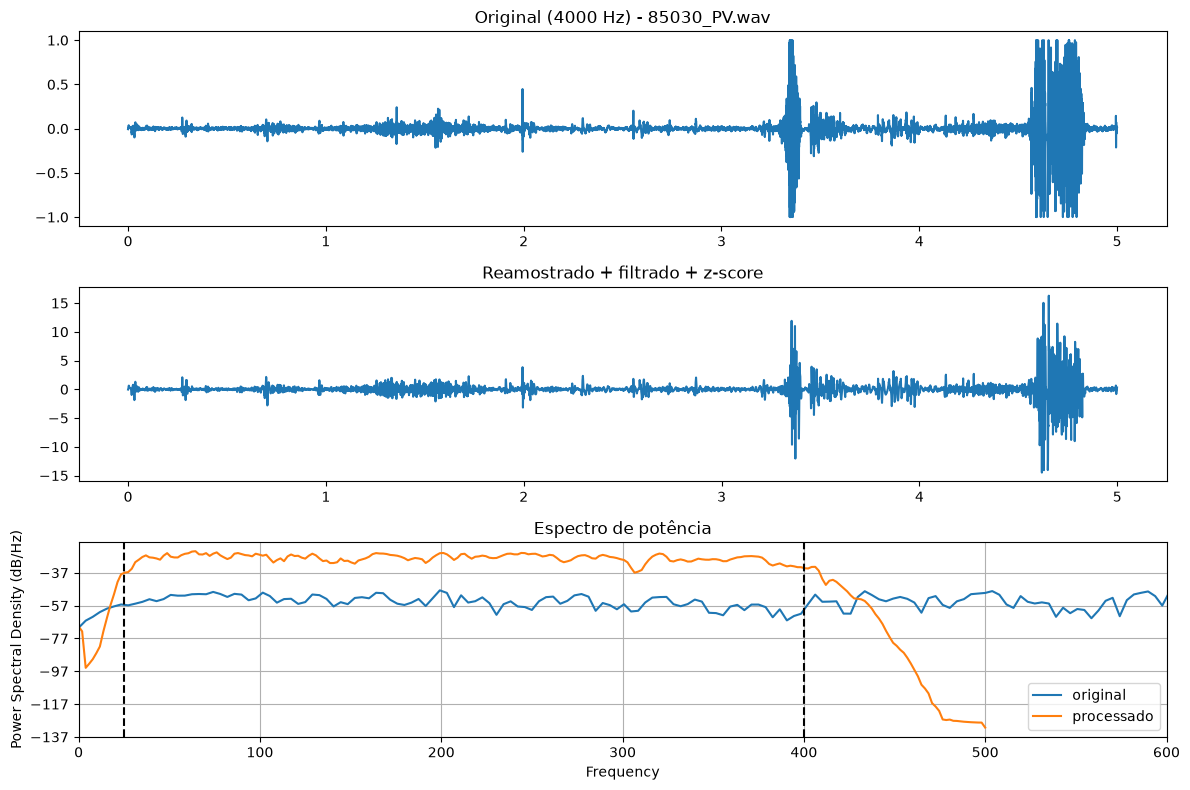

In [14]:
CLASSE = "Present"      # "Present", "Absent" ou "Unknown"
SEMENTE = None          # None = diferente em cada execução; um número = repetível

rng = np.random.default_rng(SEMENTE)
train_meta = meta[meta.pid.isin(splits["train"])]
pid = rng.choice(train_meta[train_meta.murmur == CLASSE].pid.values)
wav_path = rng.choice(sorted(CFG.wav_dir.glob(f"{pid}_*.wav")))
print("Paciente:", pid, "| classe:", CLASSE, "| ficheiro:", wav_path.name)
fs0, raw = wavfile.read(wav_path)
raw = raw.astype(np.float32) / np.abs(raw).max()
proc = load_recording(wav_path)

fig, ax = plt.subplots(3, 1, figsize=(12, 8))
t0 = np.arange(len(raw)) / fs0
t1 = np.arange(len(proc)) / CFG.fs_target
ax[0].plot(t0[:fs0 * 5], raw[:fs0 * 5]);  ax[0].set_title(f"Original ({fs0} Hz) - {wav_path.name}")
ax[1].plot(t1[:CFG.fs_target * 5], proc[:CFG.fs_target * 5]); ax[1].set_title("Reamostrado + filtrado + z-score")
ax[2].psd(raw, Fs=fs0, NFFT=1024, label="original")
ax[2].psd(proc, Fs=CFG.fs_target, NFFT=512, label="processado")
ax[2].axvline(CFG.band[0], color="k", ls="--"); ax[2].axvline(CFG.band[1], color="k", ls="--")
ax[2].set_xlim(0, 600); ax[2].legend(); ax[2].set_title("Espectro de potência")
plt.tight_layout(); plt.show()